# Monkey F: first look at the binned TVSD data

Same checks as for monkey N, with N as reference. Questions:
1. Same format as N? Trials per day, electrodes, `train_idx`; do the 4 days cover the 22,248 train images once?
2. Time courses per area: when does each area respond (window starts 25 / 50 / 75 ms)?
3. Arrays without visual response (as N's V1 channels 320-383)?
4. IT early transient (paper: 7 sites in F, 52 in N)?

Inputs: `~/Desktop/neural_data/MonkeyF/monkeyF_day{1-4}_{V1,V4,IT}_binned.npz`, monkey N files anywhere under `~/Desktop/neural_data`.

Monkey F's V4 and IT files are swapped back here: the preprocessing used monkey N's V1-V4-IT channel order, but F's order is V1-IT-V4
(TVSD paper: F has 3 V4 arrays = 192 electrodes, 5 IT arrays = 320). So F's IT = the file named V4, F's V4 = the file named IT
(same as `Round1/clean_monkeyF.py` on Torch).
Response strength d' per channel = (mean response in the area's window − mean baseline 0-20 ms) / SD of the baseline across trials.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=RuntimeWarning)

NEURAL = Path("~/Desktop/neural_data").expanduser()
monkeys, areas, days = ["monkeyF", "monkeyN"], ["V1", "V4", "IT"], [1, 2, 3, 4]
N_DROP = np.arange(320, 384)                                   # monkey N V1 channels without response (Round 1)
file_label = {"monkeyN": {"V1": "V1", "V4": "V4", "IT": "IT"},
              "monkeyF": {"V1": "V1", "V4": "IT", "IT": "V4"}}  # area -> label in the file name (F: V4 and IT swapped)
t_ms = np.arange(20) * 10 + 5                                  # bin centers
base_bins = [0, 1]                                             # 0-20 ms, before any response
resp_bins = {"V1": np.arange(3, 11), "V4": np.arange(5, 15), "IT": np.arange(7, 18)}

rows, tc, ch_tc, dprime, idx = [], {}, {}, {}, {}
for m in monkeys:
    for d in days:
        for a in areas:
            f = next(NEURAL.rglob(f"{m}_day{d}_{file_label[m][a]}_binned.npz"))
            z = np.load(f)
            mua = z["binned_mua"].astype(np.float32)           # (20, trials, electrodes)
            if m == "monkeyN" and a == "V1":
                mua = np.delete(mua, N_DROP, axis=2)
            base = mua[base_bins].mean(0)                       # (trials, electrodes)
            resp = mua[resp_bins[a]].mean(0)
            dprime[m, d, a] = (resp.mean(0) - base.mean(0)) / base.std(0)
            tc[m, d, a] = mua.mean(axis=(1, 2))
            ch_tc[m, d, a] = mua.mean(axis=1)                   # (20, electrodes)
            idx[m, d, a] = z["train_idx"]
            rows.append({"monkey": m, "day": d, "area": a, "trials": mua.shape[1], "electrodes": mua.shape[2],
                         "file": f.name, "dtype": z["binned_mua"].dtype, "keys": ", ".join(z.files),
                         "train_idx min": z["train_idx"].min(), "max": z["train_idx"].max()})
info = pd.DataFrame(rows)
print(info.to_string(index=False))

 monkey  day area  trials  electrodes                       file   dtype                  keys  train_idx min   max
monkeyF    1   V1    4475         512 monkeyF_day1_V1_binned.npz float32 binned_mua, train_idx              5 22246
monkeyF    1   V4    4475         192 monkeyF_day1_IT_binned.npz float32 binned_mua, train_idx              5 22246
monkeyF    1   IT    4475         320 monkeyF_day1_V4_binned.npz float32 binned_mua, train_idx              5 22246
monkeyF    2   V1    6184         512 monkeyF_day2_V1_binned.npz float32 binned_mua, train_idx              4 22247
monkeyF    2   V4    6184         192 monkeyF_day2_IT_binned.npz float32 binned_mua, train_idx              4 22247
monkeyF    2   IT    6184         320 monkeyF_day2_V4_binned.npz float32 binned_mua, train_idx              4 22247
monkeyF    3   V1    6307         512 monkeyF_day3_V1_binned.npz float32 binned_mua, train_idx             10 22243
monkeyF    3   V4    6307         192 monkeyF_day3_IT_binned.npz float32

## 1. Trials and images

In [ ]:
stims = {}
for m in monkeys:
    for d in days:
        same = all(np.array_equal(idx[m, d, a], idx[m, d, "V1"]) for a in areas)
        print(f"{m} day {d}: {len(idx[m, d, 'V1'])} trials, train_idx identical across areas: {same}")
    allidx = np.concatenate([idx[m, d, "V1"] for d in days])
    stims[m] = set(allidx.tolist())
    print(f"{m}: {len(allidx)} trials, {len(stims[m])} unique images, "
          f"= 1..22248 exactly once: {np.array_equal(np.sort(allidx), np.arange(1, 22249))}")
print("same image set in both monkeys:", stims["monkeyF"] == stims["monkeyN"])

# which F day each image is in, against its N day (rows: N day, columns: F day)
day_of = {m: {s: d for d in days for s in idx[m, d, "V1"].tolist()} for m in monkeys}
cross = pd.crosstab(pd.Series([day_of["monkeyN"][s] for s in sorted(stims["monkeyN"])], name="N day"),
                    pd.Series([day_of["monkeyF"].get(s, 0) for s in sorted(stims["monkeyN"])], name="F day"))
print(cross)

monkeyF day 1: 4475 trials, train_idx identical across areas: True
monkeyF day 2: 6184 trials, train_idx identical across areas: True
monkeyF day 3: 6307 trials, train_idx identical across areas: True
monkeyF day 4: 5282 trials, train_idx identical across areas: True
monkeyF: 22248 trials, 22248 unique images, = 1..22248 exactly once: True
monkeyN day 1: 9176 trials, train_idx identical across areas: True
monkeyN day 2: 5855 trials, train_idx identical across areas: True
monkeyN day 3: 4602 trials, train_idx identical across areas: True
monkeyN day 4: 2615 trials, train_idx identical across areas: True
monkeyN: 22248 trials, 22248 unique images, = 1..22248 exactly once: True
same image set in both monkeys: True
F day     1     2     3     4
N day                        
1      4475  4701     0     0
2         0  1483  4372     0
3         0     0  1935  2667
4         0     0     0  2615


## 2. Time courses

Top: monkey F, mean MUA over trials and electrodes, per day. Bottom: both monkeys, all days pooled, scaled to first bin = 0, peak = 1.
Dashed: TVSD window start (25 / 50 / 75 ms).

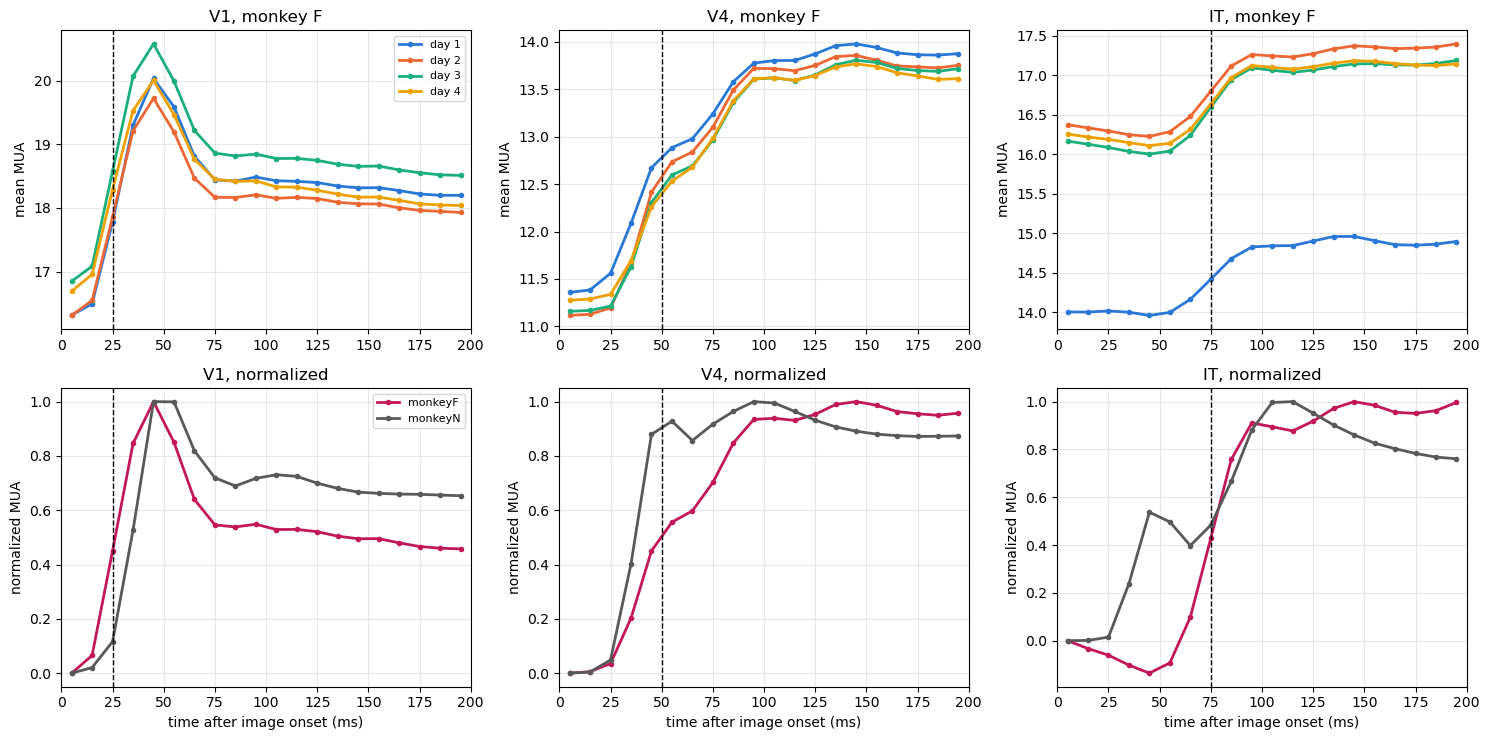

time to half of the peak (bin center, ms), all days pooled; IT also from 60 ms on (skips the early transient):
  monkeyF: V1 35  V4 55  IT 85  IT(>=60 ms) 85
  monkeyN: V1 35  V4 45  IT 45  IT(>=60 ms) 85


In [ ]:
start = {"V1": 25, "V4": 50, "IT": 75}
day_color = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
m_color = {"monkeyF": "#c2185b", "monkeyN": "0.35"}

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for j, a in enumerate(areas):
    for k, d in enumerate(days):
        axes[0, j].plot(t_ms, tc["monkeyF", d, a], "o-", color=day_color[k], lw=2, ms=3, label=f"day {d}")
    for m in monkeys:
        w = np.array([info.query("monkey == @m and day == @d and area == @a")["trials"].item() for d in days])
        c = sum(w[k] * tc[m, d, a] for k, d in enumerate(days)) / w.sum()
        axes[1, j].plot(t_ms, (c - c[0]) / (c.max() - c[0]), "o-", color=m_color[m], lw=2, ms=3, label=m)
    axes[0, j].set(title=f"{a}, monkey F", ylabel="mean MUA")
    axes[1, j].set(title=f"{a}, normalized", ylabel="normalized MUA", xlabel="time after image onset (ms)")
    for ax in axes[:, j]:
        ax.axvline(start[a], color="k", ls="--", lw=1)
        ax.set_xlim(0, 200)
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("time to half of the peak (bin center, ms), all days pooled; IT also from 60 ms on (skips the early transient):")
for m in monkeys:
    out = []
    for a in areas:
        c = sum(tc[m, d, a] for d in days)
        c = (c - c[0]) / (c.max() - c[0])
        out.append(f"{a} {t_ms[np.argmax(c >= 0.5)]}")
        if a == "IT":
            out.append(f"IT(>=60 ms) {t_ms[6 + np.argmax(c[6:] >= 0.5)]}")
    print(f"  {m}: " + "  ".join(out))

## 3. Response strength per channel (arrays without response?)

d' per channel and day; vertical lines: 64-channel array boundaries. N's V1 is shown without channels 320-383.

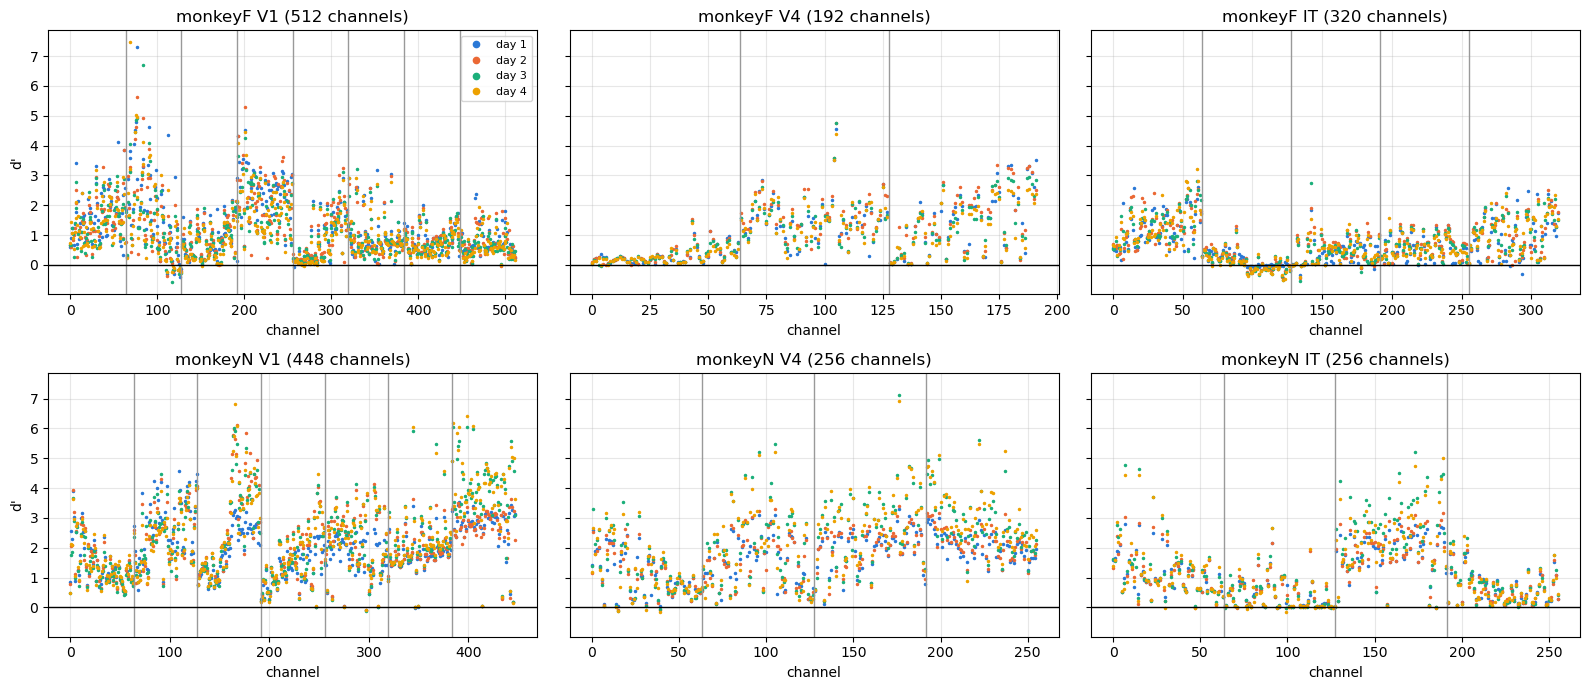

monkey F: median d' per 64-channel array (days 1-4):
  V1 channels   0- 63:  1.62   1.42   1.41   1.42
  V1 channels  64-127:  1.47   1.23   1.20   1.23
  V1 channels 128-191:  0.74   0.72   0.75   0.64   <- weak on every day
  V1 channels 192-255:  2.53   2.17   1.95   1.87
  V1 channels 256-319:  0.48   0.45   0.55   0.42   <- weak on every day
  V1 channels 320-383:  0.78   0.71   0.76   0.75   <- weak on every day
  V1 channels 384-447:  0.81   0.80   0.74   0.67   <- weak on every day
  V1 channels 448-511:  0.62   0.63   0.61   0.54   <- weak on every day
  V4 channels   0- 63:  0.23   0.23   0.22   0.22   <- weak on every day
  V4 channels  64-127:  1.49   1.59   1.51   1.50
  V4 channels 128-191:  1.52   1.57   1.33   1.32
  IT channels   0- 63:  0.99   1.24   1.21   1.19
  IT channels  64-127:  0.08   0.11   0.09   0.06   <- weak on every day
  IT channels 128-191:  0.40   0.39   0.39   0.45   <- weak on every day
  IT channels 192-255:  0.47   0.63   0.59   0.46   <- weak on 

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharey=True)
for i, m in enumerate(monkeys):
    for j, a in enumerate(areas):
        ax = axes[i, j]
        for k, d in enumerate(days):
            ax.plot(dprime[m, d, a], ".", color=day_color[k], ms=3, label=f"day {d}")
        n_ch = len(dprime[m, 1, a])
        for b in range(64, n_ch, 64):
            ax.axvline(b - 0.5, color="0.6", lw=1)
        ax.axhline(0, color="k", lw=1)
        ax.set(title=f"{m} {a} ({n_ch} channels)", xlabel="channel")
        ax.grid(alpha=0.3)
    axes[i, 0].set_ylabel("d'")
axes[0, 0].legend(fontsize=8, markerscale=3)
plt.tight_layout()
plt.show()

print("monkey F: median d' per 64-channel array (days 1-4):")
for a in areas:
    dp = np.array([dprime["monkeyF", d, a] for d in days])         # (day, channel)
    for b in range(0, dp.shape[1], 64):
        med = np.median(dp[:, b:b + 64], axis=1)
        flag = "   <- weak on every day" if (med < 1).all() else ""
        print(f"  {a} channels {b:3d}-{b + 63:3d}: " + "  ".join(f"{v:5.2f}" for v in med) + flag)

## 4. IT early transient

Each row: one IT channel, mean over trials and days, scaled to its own range (0 = min, 1 = max), sorted by peak time.
Count: channels whose response at 40-60 ms reaches half of their range (main IT response starts ~75 ms).

monkeyF: early-response IT channels: [71, 96, 97, 98, 99, 100, 101, 102, 105, 107, 108, 109, 110, 111, 113, 114, 117, 121, 122, 123, 124, 125, 127, 129, 130, 134, 135, 136, 137, 138, 143, 145, 152, 178, 219, 313, 314, 315, 316]
monkeyN: early-response IT channels: [0, 1, 2, 3, 4, 7, 8, 9, 10, 11, 12, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 60, 61, 62, 63, 64, 65, 72, 73, 74, 78, 79, 80, 81, 82, 83, 86, 87, 88, 89, 94, 95, 96, 97, 98, 99, 101, 102, 103, 107, 108, 109, 110, 111, 112, 116, 117, 118, 119, 120, 123, 124, 125, 126, 127, 139, 146, 147, 154, 155, 156, 160, 161, 162, 163, 164, 165, 168, 169, 170, 171, 173, 175, 177, 178, 179, 180, 183, 184, 185, 186, 187, 188, 189, 190, 191, 194, 208, 216, 224, 233, 240, 241, 242, 248, 249]


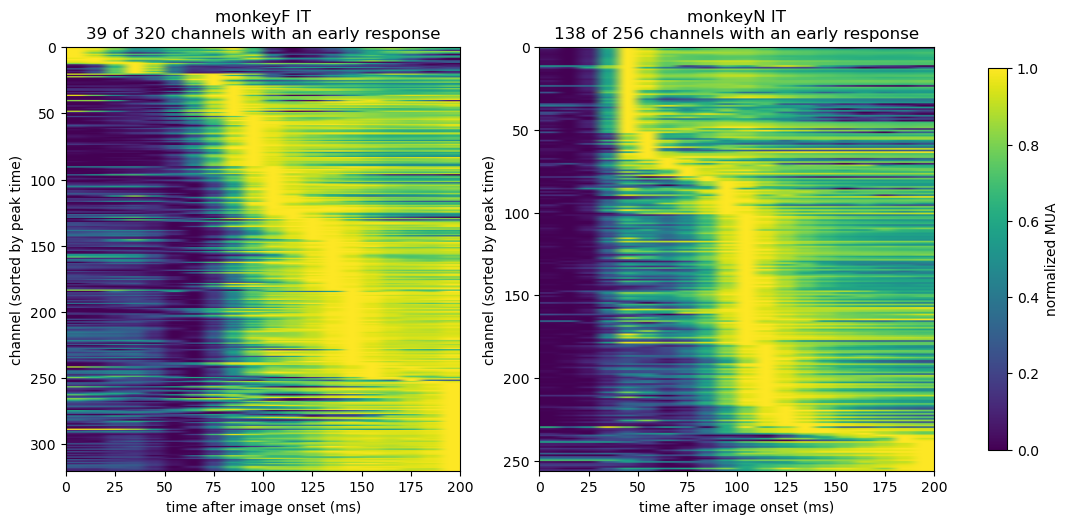

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, m in zip(axes, monkeys):
    c = sum(ch_tc[m, d, "IT"] for d in days).T                         # (channel, bin)
    c = (c - c.min(1, keepdims=True)) / (c.max(1, keepdims=True) - c.min(1, keepdims=True))
    early = (c[:, 4:6].max(1) >= 0.5)
    im = ax.imshow(c[np.argsort(c.argmax(1))], aspect="auto", cmap="viridis", extent=(0, 200, c.shape[0], 0))
    ax.set(title=f"{m} IT\n{early.sum()} of {c.shape[0]} channels with an early response",
           xlabel="time after image onset (ms)", ylabel="channel (sorted by peak time)")
    print(f"{m}: early-response IT channels: {np.where(early)[0].tolist()}")
fig.colorbar(im, ax=axes, label="normalized MUA", shrink=0.9)
plt.show()